# Regularization: linear against Ridge against Lasso

The agency liked the 2.2 model but asked why one coefficient is so large: a poor-quality garage (`GarageQual` = `Po`) cuts the predicted price by 39.2%, and only one training house has that value. You fit the same pipeline three ways, plot a learning curve for each, and recommend one model.

## The starter

The cell repeats the 2.2 setup: D01 6.4's decisions, the 75 / 25 split, `pre` (and `make_pre(X)` to build a fresh copy), a scorer `rmse_dollars` that reports errors in dollars, and the folds `cv = KFold(5, shuffle=True, random_state=42)`.

In [1]:
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.metrics import make_scorer, root_mean_squared_error
from sklearn.model_selection import KFold, learning_curve, train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

df = pd.read_csv("data/ames.csv", keep_default_na=False, na_values=[""])
df = df[df["GrLivArea"] <= 4000]
y = np.log(df["SalePrice"])
X = df.drop(columns=["Id", "SalePrice", "SaleType", "SaleCondition"])
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42)

STRUCTURAL = ["Alley", "BsmtQual", "BsmtCond", "BsmtExposure", "BsmtFinType1", "BsmtFinType2",
              "FireplaceQu", "GarageType", "GarageFinish", "GarageQual", "GarageCond", "PoolQC",
              "Fence", "MiscFeature"]


def make_pre(X):
    """D01 6.4's three-block ColumnTransformer for the columns X has."""
    num_cols = list(X.select_dtypes(include="number").columns)
    cat_cols = list(X.select_dtypes(include=["str", "object"]).columns)
    structural = [c for c in STRUCTURAL if c in cat_cols]
    other_cat = [c for c in cat_cols if c not in STRUCTURAL]
    blocks = [
        ("num", make_pipeline(SimpleImputer(strategy="median"), StandardScaler()), num_cols),
        ("none", make_pipeline(SimpleImputer(strategy="constant", fill_value="None"),
                               OneHotEncoder(handle_unknown="ignore", sparse_output=False)), structural),
        ("cat", make_pipeline(SimpleImputer(strategy="most_frequent"),
                              OneHotEncoder(handle_unknown="ignore", sparse_output=False)), other_cat),
    ]
    return ColumnTransformer([b for b in blocks if b[2]])


pre = make_pre(X)


def dollar_rmse(y_log_true, y_log_pred):
    """RMSE in dollars. The clip stops one wild prediction on a small training set from overflowing exp."""
    return root_mean_squared_error(np.exp(y_log_true), np.exp(np.clip(y_log_pred, 9, 15)))


rmse_dollars = make_scorer(dollar_rmse, greater_is_better=False)

# On the smallest learning-curve sizes no training house has a pool, so the imputer warns that
# PoolQC has no observed values and skips it. The warning is expected; this line hides it.
warnings.filterwarnings("ignore", message="Skipping features without any observed values")
cv = KFold(5, shuffle=True, random_state=42)
print(len(X_train), "training houses,", len(X_test), "test houses")

1092 training houses, 364 test houses


## Step 1 · The 2.2 model again

Refit `make_pipeline(pre, LinearRegression())` and print its test RMSE in dollars and the coefficient of `none__GarageQual_Po`. Find it with `pd.Series(model[-1].coef_, index=model[0].get_feature_names_out())`.

In [2]:
from sklearn.linear_model import LinearRegression


def test_rmse(model):
    return dollar_rmse(y_test, model.predict(X_test))


def coefs(model):
    return pd.Series(model[-1].coef_, index=model[0].get_feature_names_out())


linear = make_pipeline(make_pre(X), LinearRegression()).fit(X_train, y_train)
print(f"test RMSE {test_rmse(linear):,.0f} | GarageQual_Po {coefs(linear)['none__GarageQual_Po']:.3f}")

test RMSE 22,091 | GarageQual_Po -0.497


## Step 2 · Ridge

Replace `LinearRegression()` with `RidgeCV(alphas=np.logspace(-3, 3, 13), cv=cv)`. Print the chosen `alpha_`, the test RMSE and the same coefficient.

In [3]:
from sklearn.linear_model import RidgeCV

ridge = make_pipeline(make_pre(X), RidgeCV(alphas=np.logspace(-3, 3, 13), cv=cv)).fit(X_train, y_train)
print(f"alpha_ {ridge[-1].alpha_:.4g} | test RMSE {test_rmse(ridge):,.0f} | "
      f"GarageQual_Po {coefs(ridge)['none__GarageQual_Po']:.3f}")

alpha_ 31.62 | test RMSE 20,045 | GarageQual_Po -0.001


## Step 3 · Lasso

Replace it with `LassoCV(alphas=np.logspace(-5, -1, 13), cv=cv, max_iter=50000, random_state=42)`. Print `alpha_`, the test RMSE, the same coefficient, and how many coefficients are not zero. Count a coefficient as zero when its absolute value is below 1e-10: `(coef != 0).sum()` also counts two values near 1e-16, which are rounding leftovers.

In [4]:
from sklearn.linear_model import LassoCV

lasso = make_pipeline(make_pre(X), LassoCV(alphas=np.logspace(-5, -1, 13), cv=cv, max_iter=50000,
                                           random_state=42)).fit(X_train, y_train)
c_lasso = coefs(lasso)
kept = c_lasso.abs() > 1e-10     # two coefficients come out near 1e-16, floating-point leftovers: count them as zero
print(f"alpha_ {lasso[-1].alpha_:.4g} | test RMSE {test_rmse(lasso):,.0f} | "
      f"GarageQual_Po {c_lasso['none__GarageQual_Po']:.3f} | {kept.sum()} of {len(c_lasso)} not zero")

alpha_ 0.001 | test RMSE 19,610 | GarageQual_Po 0.000 | 75 of 283 not zero


## Step 4 · "Is the plain model memorizing our houses?"

Translate: `learning_curve` for each of the three models, on the training rows only, with `cv=cv`, `train_sizes=np.linspace(0.15, 1.0, 8)`, `scoring=rmse_dollars`, `shuffle=True, random_state=42`. Plot training and validation RMSE against the number of rows, one chart per model. Use `Ridge(alpha=...)` and `Lasso(alpha=...)` with the alphas from steps 2 and 3.

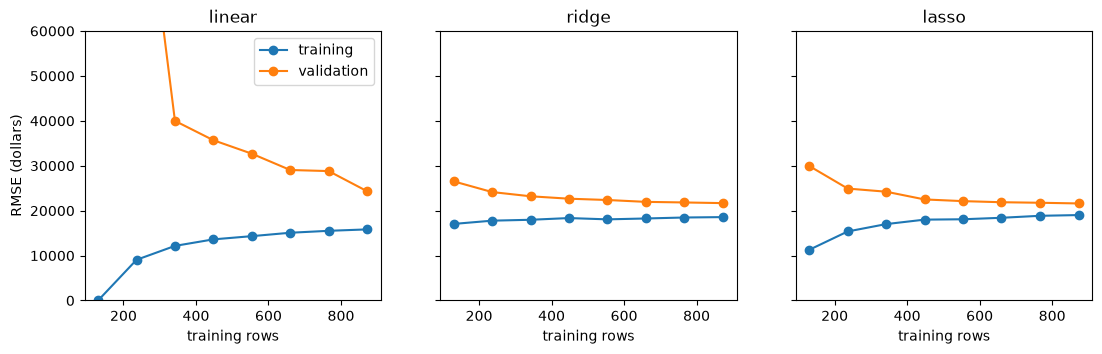

,rows,train,validation
0,130,0.0,93439.0
1,236,9058.0,108341.0
2,342,12154.0,39985.0
3,448,13610.0,35684.0
4,554,14325.0,32685.0
5,660,15083.0,29053.0
6,766,15514.0,28812.0
7,873,15833.0,24283.0


In [5]:
from sklearn.linear_model import Lasso, Ridge

candidates = {"linear": LinearRegression(), "ridge": Ridge(alpha=ridge[-1].alpha_),
              "lasso": Lasso(alpha=lasso[-1].alpha_, max_iter=50000)}
curves = {}
fig, axes = plt.subplots(1, 3, figsize=(13, 3.5), sharey=True)
for ax, (name, est) in zip(axes, candidates.items()):
    n, train_scores, val_scores = learning_curve(
        make_pipeline(make_pre(X), est), X_train, y_train, cv=cv, train_sizes=np.linspace(0.15, 1.0, 8),
        scoring=rmse_dollars, shuffle=True, random_state=42)
    train_rmse, val_rmse = -train_scores.mean(axis=1), -val_scores.mean(axis=1)
    curves[name] = pd.DataFrame({"rows": n, "train": train_rmse.round(), "validation": val_rmse.round()})
    ax.plot(n, train_rmse, marker="o", label="training")
    ax.plot(n, val_rmse, marker="o", label="validation")
    ax.set_title(name)
    ax.set_xlabel("training rows")
axes[0].set_ylabel("RMSE (dollars)")
axes[0].set_ylim(0, 60000)
axes[0].legend()
plt.show()
curves["linear"]

## Step 5 · The gap at the largest size

For each model, the gap between validation and training RMSE at the largest size.

In [6]:
for name, c in curves.items():
    last = c.iloc[-1]
    print(f"{name:<7} {int(last['rows'])} rows: gap {int(last['validation'] - last['train']):,}")

linear  873 rows: gap 8,450
ridge   873 rows: gap 3,112
lasso   873 rows: gap 2,587


## Step 6 · Recommend one model

Two sentences for the agency: which one, the test RMSE, and one thing it does that the others do not.

In [7]:
print(f"Use the Lasso model: its test error is {test_rmse(lasso):,.0f} dollars, the lowest of the three, "
      f"against {test_rmse(linear):,.0f} for the plain model. It also sets {(~kept).sum()} of the "
      f"{len(c_lasso)} coefficients to zero, so the agency gets a shorter list of what moves the price.")

Use the Lasso model: its test error is 19,610 dollars, the lowest of the three, against 22,091 for the plain model. It also sets 208 of the 283 coefficients to zero, so the agency gets a shorter list of what moves the price.


## Bonus · ElasticNet

In [8]:
from sklearn.linear_model import ElasticNetCV

enet = make_pipeline(make_pre(X), ElasticNetCV(l1_ratio=[0.2, 0.5, 0.8], alphas=np.logspace(-5, -1, 13), cv=cv,
                                               max_iter=50000, random_state=42)).fit(X_train, y_train)
print(f"l1_ratio_ {enet[-1].l1_ratio_} | {(coefs(enet).abs() > 1e-10).sum()} kept | test RMSE {test_rmse(enet):,.0f}")

l1_ratio_ 0.8 | 83 kept | test RMSE 19,517


## Check yourself

In [9]:
first = curves["linear"].iloc[0]
check = {
    "Step 1 · linear test RMSE": round(test_rmse(linear)),
    "Step 1 · linear GarageQual_Po": f"{coefs(linear)['none__GarageQual_Po']:.3f}",
    "Step 2 · ridge alpha_": f"{ridge[-1].alpha_:.4g}",
    "Step 2 · ridge test RMSE": round(test_rmse(ridge)),
    "Step 2 · ridge GarageQual_Po": f"{coefs(ridge)['none__GarageQual_Po']:.3f}",
    "Step 3 · lasso alpha_": f"{lasso[-1].alpha_:.4g}",
    "Step 3 · lasso test RMSE": round(test_rmse(lasso)),
    "Step 3 · lasso coefficients not zero": kept.sum(),
    "Step 3 · coefficients in all": len(c_lasso),
    "Step 3 · lasso GarageQual_Po": f"{c_lasso['none__GarageQual_Po']:.3f}",
    "Step 4 · linear, smallest size": f"{int(first['rows'])} rows: train {int(first['train'])}, validation {int(first['validation'])}",
    "Step 5 · rows at the largest size": int(curves["linear"].iloc[-1]["rows"]),
    "Step 5 · linear gap": int(curves["linear"].iloc[-1]["validation"] - curves["linear"].iloc[-1]["train"]),
    "Step 5 · ridge gap": int(curves["ridge"].iloc[-1]["validation"] - curves["ridge"].iloc[-1]["train"]),
    "Step 5 · lasso gap": int(curves["lasso"].iloc[-1]["validation"] - curves["lasso"].iloc[-1]["train"]),
    "Bonus · l1_ratio_": enet[-1].l1_ratio_,
    "Bonus · coefficients kept": (coefs(enet).abs() > 1e-10).sum(),
    "Bonus · test RMSE": round(test_rmse(enet)),
}
for label, value in check.items():
    print(f"{label:<38} {value}")

Step 1 · linear test RMSE              22091
Step 1 · linear GarageQual_Po          -0.497
Step 2 · ridge alpha_                  31.62
Step 2 · ridge test RMSE               20045
Step 2 · ridge GarageQual_Po           -0.001
Step 3 · lasso alpha_                  0.001
Step 3 · lasso test RMSE               19610
Step 3 · lasso coefficients not zero   75
Step 3 · coefficients in all           283
Step 3 · lasso GarageQual_Po           0.000
Step 4 · linear, smallest size         130 rows: train 0, validation 93439
Step 5 · rows at the largest size      873
Step 5 · linear gap                    8450
Step 5 · ridge gap                     3112
Step 5 · lasso gap                     2587
Bonus · l1_ratio_                      0.8
Bonus · coefficients kept              83
Bonus · test RMSE                      19517
